<a href="https://colab.research.google.com/github/HadisaMaryam/CAkeBAking-/blob/main/pharmacy_stockout_risk_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PHARMACY DATASET
   Current_Stock  Daily_Sales  Supplier_Lead_Time  Demand_Variability  \
0            107            8                   3            0.290795   
1            184           10                   7            0.691618   
2             97           25                   3            0.525054   
3             19            7                  12            0.892141   
4            111            3                   3            0.294167   

   Supplier_Reliability  Reorder_Level  Pending_Order  Days_Stock_Cover  \
0              0.978816             10             65         13.375000   
1              0.782872             96             29         18.400000   
2              0.757231             83             19          3.880000   
3              0.542528             51             59          2.714286   
4              0.774436             61             81         37.000000   

   Stockout_Risk  
0              0  
1              0  
2              1  
3              1 

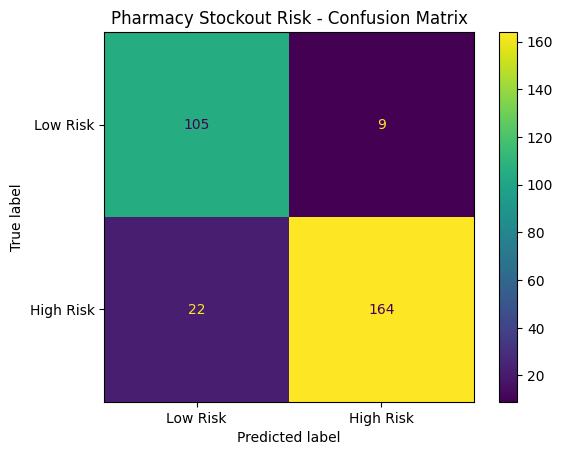

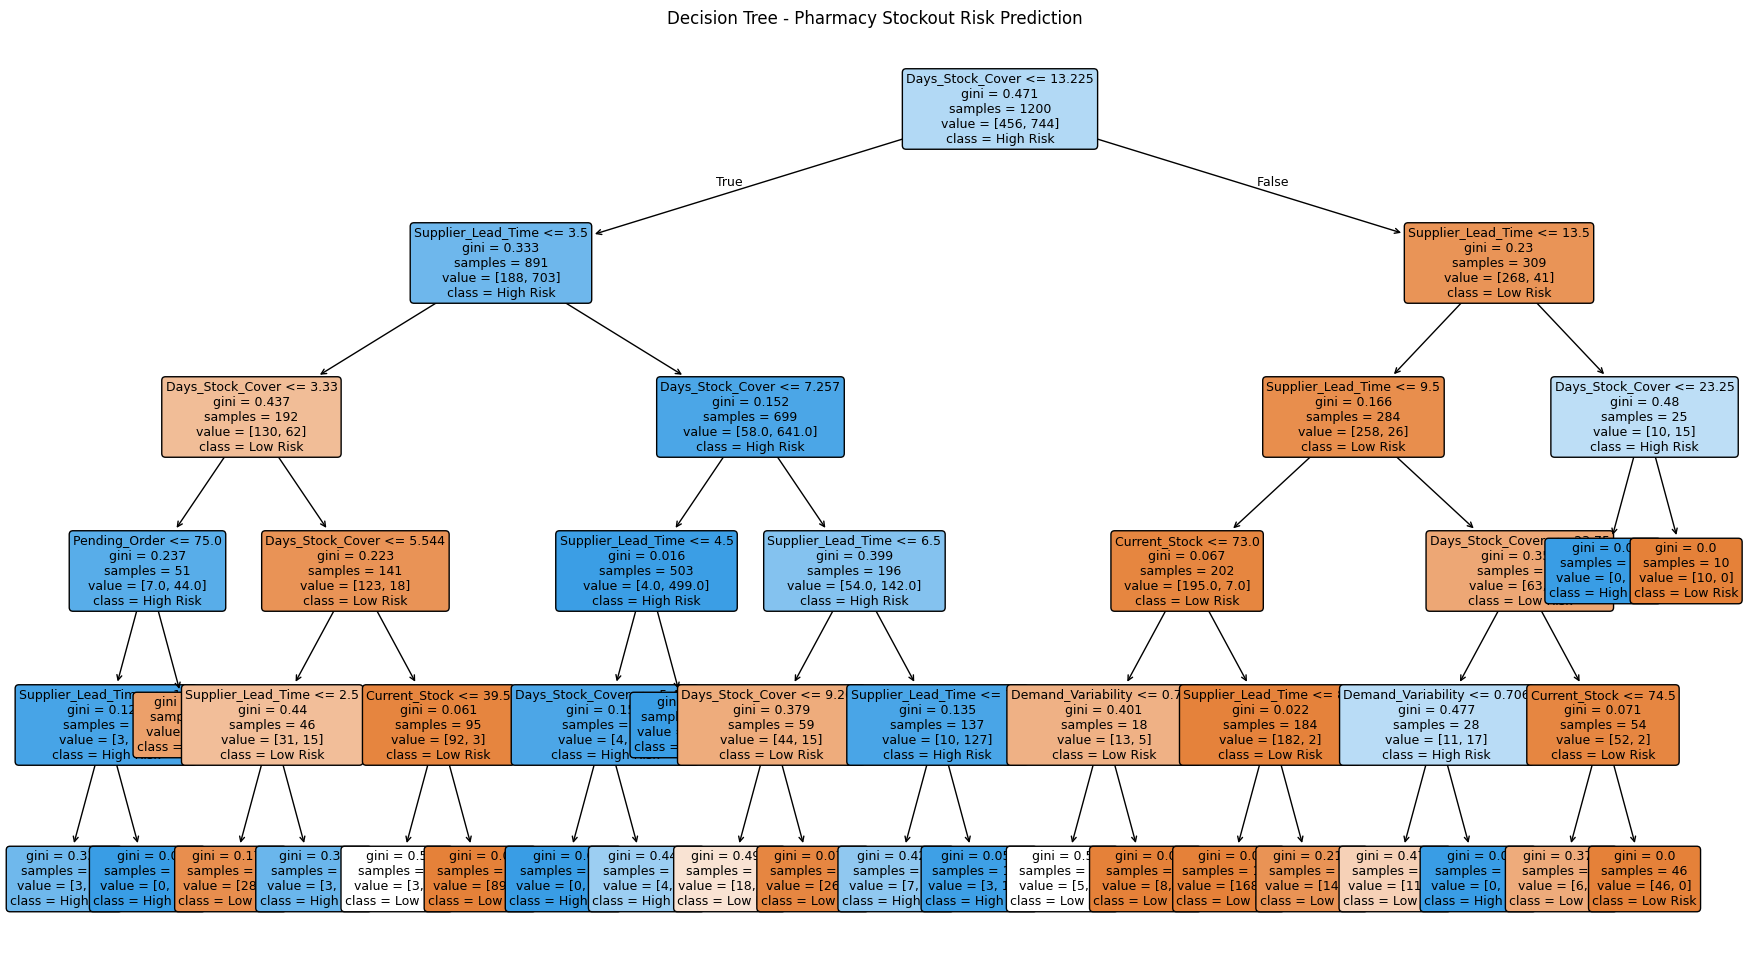


FEATURE IMPORTANCE:
                Feature  Importance
7      Days_Stock_Cover    0.604103
2    Supplier_Lead_Time    0.359177
3    Demand_Variability    0.014415
0         Current_Stock    0.012311
6         Pending_Order    0.009994
1           Daily_Sales    0.000000
5         Reorder_Level    0.000000
4  Supplier_Reliability    0.000000


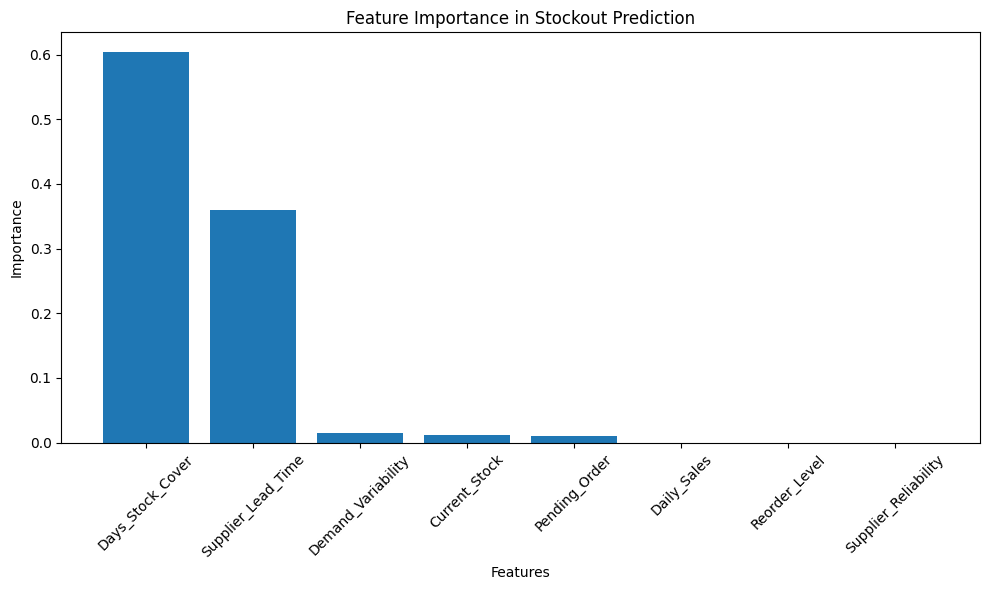


NEW MEDICINE PREDICTION
Stockout Risk: HIGH
Estimated High-Risk Probability: 100.0 %

PHARMACY STOCKOUT PREDICTION COMPLETE
Algorithm: Decision Tree Classifier
Total Dataset Records: 1500
Training Records: 1200
Testing Records: 300
Model Accuracy: 89.67 %


In [5]:
# =====================================================
# PROJECT: PHARMACY STOCKOUT RISK PREDICTION
# ALGORITHM: DECISION TREE CLASSIFIER
# =====================================================


# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# STEP 2: CREATE PHARMACY DATASET

np.random.seed(42)

number_of_records = 1500

data = pd.DataFrame({

    "Current_Stock": np.random.randint(5, 200, number_of_records),

    "Daily_Sales": np.random.randint(1, 30, number_of_records),

    "Supplier_Lead_Time": np.random.randint(1, 15, number_of_records),

    "Demand_Variability": np.random.uniform(0.1, 1.0, number_of_records),

    "Supplier_Reliability": np.random.uniform(0.5, 1.0, number_of_records),

    "Reorder_Level": np.random.randint(10, 100, number_of_records),

    "Pending_Order": np.random.randint(0, 100, number_of_records)

})


# STEP 3: FEATURE ENGINEERING

# Calculate how many days the current stock can last

data["Days_Stock_Cover"] = (
    data["Current_Stock"] / data["Daily_Sales"]
)


# STEP 4: CREATE TARGET VARIABLE

# 1 = High stockout risk
# 0 = Low stockout risk

data["Stockout_Risk"] = (

    (data["Days_Stock_Cover"] <
     data["Supplier_Lead_Time"] *
     (1 + data["Demand_Variability"]))

    |

    (

        (data["Current_Stock"] <
         data["Reorder_Level"])

        &

        (data["Supplier_Reliability"] < 0.75)

    )

).astype(int)


# STEP 5: DISPLAY DATASET

print("PHARMACY DATASET")
print(data.head())

print("\nDataset Shape:", data.shape)

print("\nStockout Risk Distribution:")
print(data["Stockout_Risk"].value_counts())


# STEP 6: SELECT INPUT FEATURES AND TARGET

X = data.drop("Stockout_Risk", axis=1)

y = data["Stockout_Risk"]


# STEP 7: SPLIT DATA INTO TRAINING AND TESTING

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y

)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))


# STEP 8: CREATE DECISION TREE MODEL

model = DecisionTreeClassifier(

    criterion="gini",
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42

)


# STEP 9: TRAIN THE MODEL

model.fit(X_train, y_train)

print("\nDecision Tree Model Successfully Trained!")


# STEP 10: MAKE PREDICTIONS

y_pred = model.predict(X_test)


# STEP 11: EVALUATE MODEL PERFORMANCE

accuracy = accuracy_score(y_test, y_pred)

print("\nMODEL ACCURACY:")
print(accuracy * 100, "%")


print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))


# STEP 12: CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

print("\nCONFUSION MATRIX:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Risk", "High Risk"]
).plot()

plt.title("Pharmacy Stockout Risk - Confusion Matrix")
plt.show()


# STEP 13: VISUALIZE DECISION TREE

plt.figure(figsize=(22, 12))

plot_tree(

    model,

    feature_names=X.columns,

    class_names=["Low Risk", "High Risk"],

    filled=True,

    rounded=True,

    fontsize=9

)

plt.title("Decision Tree - Pharmacy Stockout Risk Prediction")

plt.show()


# STEP 14: FEATURE IMPORTANCE

importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": model.feature_importances_

})

importance = importance.sort_values(

    by="Importance",

    ascending=False

)

print("\nFEATURE IMPORTANCE:")
print(importance)


plt.figure(figsize=(10, 6))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xticks(rotation=45)

plt.title("Feature Importance in Stockout Prediction")

plt.xlabel("Features")

plt.ylabel("Importance")

plt.tight_layout()

plt.show()


# STEP 15: PREDICT STOCKOUT RISK FOR A NEW MEDICINE

new_medicine = pd.DataFrame({

    "Current_Stock": [20],

    "Daily_Sales": [10],

    "Supplier_Lead_Time": [7],

    "Demand_Variability": [0.8],

    "Supplier_Reliability": [0.6],

    "Reorder_Level": [40],

    "Pending_Order": [0],

    "Days_Stock_Cover": [20 / 10]

})


prediction = model.predict(new_medicine)

probability = model.predict_proba(new_medicine)


print("\nNEW MEDICINE PREDICTION")

if prediction[0] == 1:

    print("Stockout Risk: HIGH")

else:

    print("Stockout Risk: LOW")


print(
    "Estimated High-Risk Probability:",
    round(probability[0][1] * 100, 2),
    "%"
)


# STEP 16: FINAL PROJECT MESSAGE

print("\n===================================")

print("PHARMACY STOCKOUT PREDICTION COMPLETE")

print("Algorithm: Decision Tree Classifier")

print("Total Dataset Records:", number_of_records)

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("===================================")